In [ ]:
import pandas as pd
import numpy as np

# For splitting the dataset
from sklearn.model_selection import train_test_split

# For Support Vector Machine
from sklearn.svm import SVC

# For evaluation
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

In [7]:
#Load the file
import pandas as pd
df = pd.read_csv("german_credit_data.csv")

In [ ]:
# Display first 5 rows
print(df.head())

# Display the shape
print(df.shape)

# Display column names
print(df.columns)

   laufkont  laufzeit  moral  verw  hoehe  sparkont  beszeit  rate  famges  \
0         1        18      4     2   1049         1        2     4       2   
1         1         9      4     0   2799         1        3     2       3   
2         2        12      2     9    841         2        4     2       2   
3         1        12      4     0   2122         1        3     3       3   
4         1        12      4     0   2171         1        3     4       3   

   buerge  ...  verm  alter  weitkred  wohn  bishkred  beruf  pers  telef  \
0       1  ...     2     21         3     1         1      3     2      1   
1       1  ...     1     36         3     1         2      3     1      1   
2       1  ...     1     23         3     1         1      2     2      1   
3       1  ...     1     39         3     1         2      2     1      1   
4       1  ...     2     38         1     2         2      2     2      1   

   gastarb  kredit  
0        2       1  
1        2       1  
2    

In [ ]:
# Features (Independent variables)
X = df.drop("kredit", axis=1)

# Target (Dependent variable)
y = df["kredit"]

# Check the shapes
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (1000, 20)
Shape of y: (1000,)


In [ ]:
print(y.value_counts())

kredit
1    700
0    300
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Check the shapes
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (800, 20)
X_test : (200, 20)
y_train: (800,)
y_test : (200,)


In [ ]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(random_state=42, max_iter=10000)
svm_model.fit(X_train, y_train)

LinearSVC(max_iter=10000, random_state=42)

In [ ]:
# Predict the credit status for the test data
y_pred = svm_model.predict(X_test)

# Display the first 10 predictions
print(y_pred[:10])

[0 1 1 1 1 1 1 1 1 1]


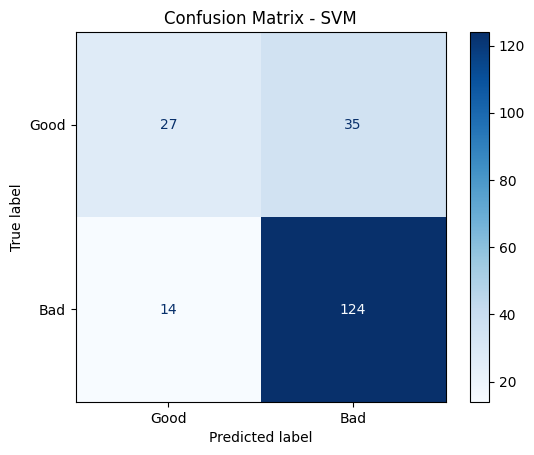

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Plot the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Good", "Bad"])
disp.plot(cmap="Blues")

plt.title("Confusion Matrix - SVM")
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy: {:.2f}%".format(accuracy * 100))

Accuracy: 75.50%
